# 01 — Analisis Audio Operator ATC

> **Dataset:** ATCOSIM, HF variant · **Modalitas:** audio · **Target:** tidak ada label fatigue  
> **Unit:** potongan ujaran (*utterance*) · **Mode default:** DEMO, hasil tersimpan + ekstraksi contoh langsung

[README proyek](../../README.md) · [Sumber HF](https://huggingface.co/datasets/Jzuluaga/atcosim_corpus) · [Audit dataset](../../reports/dataset_audit.md) · [Petunjuk reproduksi](README.md)

## Ringkasan untuk Pembaca

Suara operator memuat pola nada, energi, dan spektrum yang bisa diubah menjadi angka. Di sini kita mengikuti proses tersebut dari berkas audio sampai tabel fitur, sambil memeriksa kualitasnya. ATCOSIM berisi simulasi komunikasi ATC tanpa penilaian fatigue: keberhasilan ekstraksi belum menjawab apakah operator lelah.

Satu sel konfigurasi berikut memilih DEMO/FULL. **DEMO** membaca hasil FULL yang checksum-nya cocok dan tetap mengekstrak satu contoh asli; **FULL** memproses seluruh subset lokal ke run baru. Tidak ada unduhan otomatis.

In [1]:
from pathlib import Path
import os
RUN_MODE = os.environ.get('ATC_NOTEBOOK_MODE', 'DEMO').upper()
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'configs/notebook_v3.yaml').exists())
os.chdir(ROOT)
import yaml
config = yaml.safe_load(Path('configs/notebook_v3.yaml').read_text())
for key in ('OMP_NUM_THREADS', 'OPENBLAS_NUM_THREADS', 'MKL_NUM_THREADS', 'NUMBA_NUM_THREADS'):
    os.environ[key] = str(config['threads'])
os.environ['OPENCV_FFMPEG_THREADS'] = str(config['opencv_threads'])
import json, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Markdown, display
from threadpoolctl import threadpool_limits
from atc_fatigue.research.runs import Run, cached_run, project_config, mode_from_environment, metrics_base, save_model
from atc_fatigue.research.data import local_manifest, frozen_split, prediction_table, public_errors, verify_cached_predictions
from atc_fatigue.research.plots import (COLORS, EMOTIONS, FigureBook, theme, run_card, flow,
                                      histogram, model_bars, confusion_pair, split_chart, recall_chart)
config = project_config()
RUN_MODE = mode_from_environment(config['mode_default'])
thread_limit = threadpool_limits(limits=config['threads'])
theme()
warning_context = warnings.catch_warnings(record=True)
warning_records = warning_context.__enter__()
print(f'Mode {RUN_MODE} | CPU maksimal {config["threads"]} thread | offline | kernel proyek')

Mode DEMO | CPU maksimal 4 thread | offline | kernel proyek


[proyek]/.venv/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 1. Pertanyaan dan batas penelitian

**Pertanyaan:** dapatkah potongan suara ATC diolah konsisten menjadi fitur numerik untuk penelitian berlabel kelak?

**Fatigue** adalah kelelahan akibat tuntutan berkelanjutan. **Sleepiness** berarti kecenderungan tertidur; **workload** adalah tuntutan mental; **stress** adalah respons terhadap tekanan; **emotion** adalah emosi; **eye state** adalah keadaan mata. Target tersebut berbeda.

Kita dapat memeriksa keberhasilan pembacaan, preprocessing dan ekstraksi. Kita belum dapat menghitung akurasi fatigue. CLC (*closed-loop communication*) memerlukan readback pilot; suara ATC saja tidak cukup untuk mengukur kepatuhan readback maupun latency respons terhadap pilot.

In [2]:
audio_manifest = local_manifest(config['audio']['source_manifest'], target=None)
audio_rights = {
    'source': 'https://huggingface.co/datasets/Jzuluaga/atcosim_corpus',
    'variant': 'HF 16 kHz; observed revision ' + str(audio_manifest.hub_revision_observed.iloc[0]),
    'rights': 'research/development; source terms retained; raw media not redistributed',
    'public_preview': 'synthetic waveform/spectrogram; actual numeric features and safe aggregates',
}
audio_limits = ['first viewer rows, one speaker/session; not representative',
                'no fatigue labels; utterance duration is not VAD speech duration',
                'not continuous radio or an ATC-to-pilot response timeline']
if RUN_MODE == 'FULL':
    audio_run = Run.create('atcosim_audio', '01_audio_analysis.ipynb', config, audio_manifest,
                           'audio-egemapsv02-mfcc13-v1', audio_rights, audio_limits)
else:
    audio_run, audio_metrics = cached_run('atcosim_audio', config)
audio_book = FigureBook(audio_run, RUN_MODE, config)
run_card(audio_run, RUN_MODE, 'N/A — tidak ada ground truth fatigue')

| Identitas run | Nilai |
| :--- | :--- |
| Mode | **DEMO / CACHED — hasil FULL terverifikasi; contoh ekstraksi/inference diproses langsung** |
| Run ID sumber | `20261022T081753373596Z_seed42_72a678` |
| Status eksperimen sumber | completed |
| Dataset / target | atcosim / tidak ada label fatigue |
| Sampel / subjek | 100 / 1 |
| Unit evaluasi | utterance |
| Hasil utama | N/A — tidak ada ground truth fatigue |

## 2. Mengenal data dan provenance

Sumber asli adalah korpus simulasi TU Graz; varian HF yang tersedia telah diubah menjadi 16 kHz. Unitnya potongan ujaran, bukan seluruh sesi yang memiliki jam bersama. Hitungan berikut dibaca dari manifest aktual; checksum seluruh file telah diverifikasi sebelum pengolahan.

Hak sumber digunakan untuk riset lokal. Karena izin redistribusi waveform/rekaman belum diverifikasi secara khusus, notebook ini tidak menyertakan pemutar suara atau sinyal suara peserta. Grafik sinyal di bawah memakai **ILUSTRASI SINTETIS**, terpisah dari data untuk pengukuran dan tabel fitur.

In [3]:
display(pd.DataFrame([{
    'Ujaran': len(audio_manifest), 'Speaker': audio_manifest.subject_id.nunique(),
    'Sesi': audio_manifest.session_id.nunique(), 'Label fatigue': audio_manifest.target_value.notna().sum(),
    'Berkas tersedia': sum(Path(p).exists() for p in audio_manifest.original_path),
}]))
display(audio_manifest[['subject_id', 'session_id', 'viewer_split', 'timeline']].drop_duplicates())
display(pd.DataFrame({'Metadata transkrip': ['Tersedia pada manifest lokal'],
                      'Checksum': ['SHA-256 cocok untuk seluruh file'],
                      'Sumber contoh': ['HF variant; source revision dicatat pada run manifest']}))

,Ujaran,Speaker,Sesi,Label fatigue,Berkas tersedia
0,100,1,1,0,100


,subject_id,session_id,viewer_split,timeline
0,sm1,sm1_01,train,utterance_relative_not_continuous_session


,Metadata transkrip,Checksum,Sumber contoh
0,Tersedia pada manifest lokal,SHA-256 cocok untuk seluruh file,HF variant; source revision dicatat pada run m...


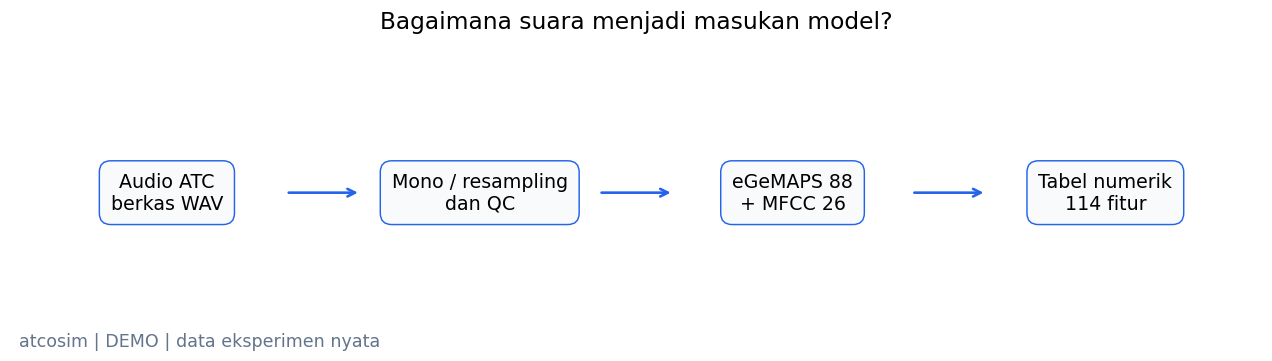

**Yang terlihat:** Alur berakhir pada 114 fitur akustik per ujaran, tanpa kelas fatigue.

**Artinya:** Representasi numerik memungkinkan pengujian model ketika label yang tepat tersedia.

**Perlu diingat:** Diagram menjelaskan proses; tidak menggambarkan model fatigue yang sudah dilatih.

*Sumber: `20261022T081753373596Z_seed42_72a678` · CACHED + contoh diproses langsung.*

In [4]:
fig = flow(['Audio ATC\nberkas WAV', 'Mono / resampling\ndan QC', 'eGeMAPS 88\n+ MFCC 26', 'Tabel numerik\n114 fitur'],
           COLORS['audio'], 'Bagaimana suara menjadi masukan model?')
audio_book.show(fig, 'audio_ke_fitur',
                'Alur berakhir pada 114 fitur akustik per ujaran, tanpa kelas fatigue.',
                'Representasi numerik memungkinkan pengujian model ketika label yang tepat tersedia.',
                'Diagram menjelaskan proses; tidak menggambarkan model fatigue yang sudah dilatih.')

## 3. Data mentah dan preprocessing nyata

**Mono** merangkum kanal menjadi satu sinyal. **Resampling** mengubah jumlah sampel per detik agar sesuai extractor; tidak menambahkan informasi baru. Tidak ada denoising tersembunyi atau normalisasi amplitudo yang mengubah statistik suara. Untuk sampel yang sudah mono 16 kHz, perubahan format memang minimal.

In [5]:
import soundfile as sf
from atc_fatigue.audio.features import extract_file, feature_names, resample
sample_audio = audio_manifest.iloc[0]
raw_signal, source_rate = sf.read(sample_audio.original_path, always_2d=True)
mono_signal = raw_signal.mean(axis=1)
prepared_signal = resample(mono_signal, source_rate, config['audio']['sample_rate'])
display(pd.DataFrame([
    {'Tahap': 'Sebelum', 'Kanal': raw_signal.shape[1], 'Sample rate (Hz)': source_rate,
     'Durasi (s)': len(raw_signal)/source_rate, 'RMS (amplitudo relatif)': np.sqrt(np.mean(raw_signal**2))},
    {'Tahap': 'Sesudah', 'Kanal': 1, 'Sample rate (Hz)': config['audio']['sample_rate'],
     'Durasi (s)': len(prepared_signal)/config['audio']['sample_rate'],
     'RMS (amplitudo relatif)': np.sqrt(np.mean(prepared_signal**2))},
]))
live_audio_features = extract_file(sample_audio.original_path, config['audio'])
audio_columns = feature_names(config['audio']['n_mfcc'])
assert len(audio_columns) == 114 and len([c for c in audio_columns if c.startswith('egemaps__')]) == 88
display(pd.Series(live_audio_features)[audio_columns[:4] + ['mfcc_00_mean', 'mfcc_00_std']].to_frame('Nilai contoh asli — FRESH'))

,Tahap,Kanal,Sample rate (Hz),Durasi (s),RMS (amplitudo relatif)
0,Sebelum,1,16000,3.299812,0.039489
1,Sesudah,1,16000,3.299812,0.039489


,Nilai contoh asli — FRESH
egemaps__F0semitoneFrom27.5Hz_sma3nz_amean,34.928963
egemaps__F0semitoneFrom27.5Hz_sma3nz_stddevNorm,0.25542
egemaps__F0semitoneFrom27.5Hz_sma3nz_percentile20.0,26.382868
egemaps__F0semitoneFrom27.5Hz_sma3nz_percentile50.0,31.587996
mfcc_00_mean,-300.372742
mfcc_00_std,136.381836


### Membaca bentuk sinyal tanpa membagikan suara peserta

Ilustrasi deterministik berikut terdiri dari tiga gelombang harmonik dan perubahan amplitudo; ini **bukan suara ATC**. Sumbu waktu tetap detik. Contoh memperlihatkan perubahan representasi stereo 32 kHz menjadi mono 16 kHz; tabel sebelumnya menunjukkan preprocessing pada file asli.

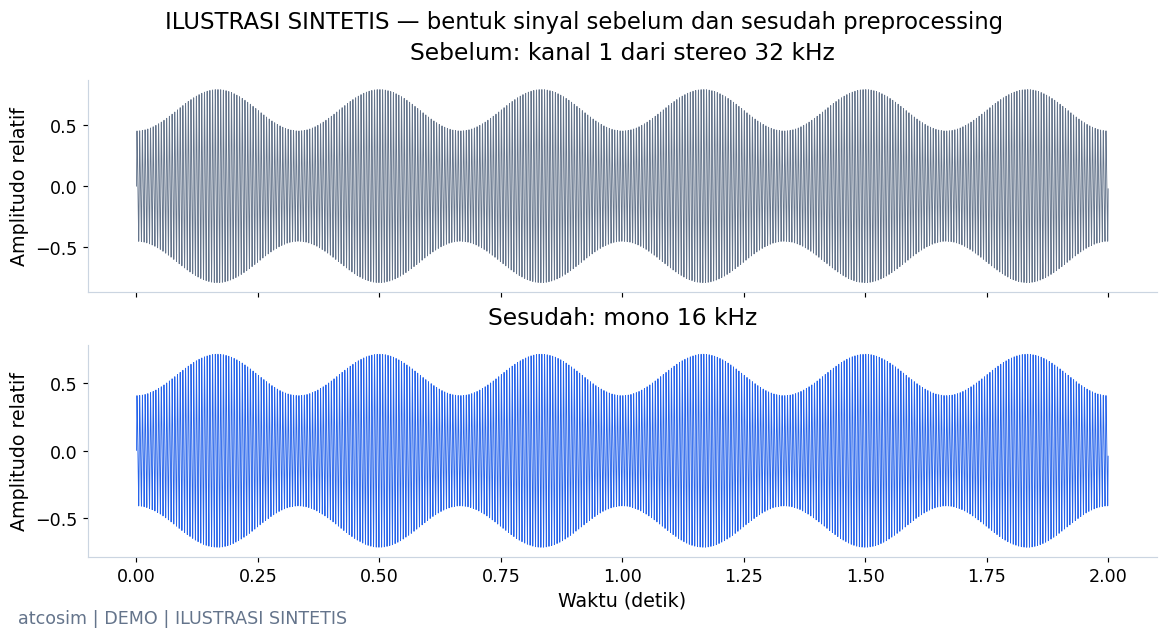

**Yang terlihat:** Sinyal dua detik mempertahankan durasi setelah jumlah sampel per detik diubah.

**Artinya:** Resampling menyamakan format masukan extractor, bukan membuat label.

**Perlu diingat:** Sinyal ini buatan dan tidak masuk eksperimen atau skor.

*Sumber: `20261022T081753373596Z_seed42_72a678` · CACHED + contoh diproses langsung.*

In [6]:
illustration_rate = 32000
illustration_time = np.arange(illustration_rate * 2) / illustration_rate
envelope = 0.4 + 0.3 * np.sin(2*np.pi*1.5*illustration_time)**2
synthetic_mono = envelope * (np.sin(2*np.pi*180*illustration_time) + 0.3*np.sin(2*np.pi*360*illustration_time))
synthetic_stereo = np.column_stack([synthetic_mono, synthetic_mono*0.8])
synthetic_prepared = resample(synthetic_stereo.mean(axis=1), illustration_rate, 16000)
fig, axes = plt.subplots(2, 1, figsize=(11, 5.8), layout='constrained', sharex=True)
axes[0].plot(illustration_time, synthetic_stereo[:, 0], color=COLORS['secondary'], lw=0.6)
axes[1].plot(np.arange(len(synthetic_prepared))/16000, synthetic_prepared, color=COLORS['audio'], lw=0.6)
for ax, label in zip(axes, ['Sebelum: kanal 1 dari stereo 32 kHz', 'Sesudah: mono 16 kHz']):
    ax.set(ylabel='Amplitudo relatif', title=label)
axes[1].set_xlabel('Waktu (detik)')
fig.suptitle('ILUSTRASI SINTETIS — bentuk sinyal sebelum dan sesudah preprocessing')
audio_book.show(fig, 'waveform_sintetis',
                'Sinyal dua detik mempertahankan durasi setelah jumlah sampel per detik diubah.',
                'Resampling menyamakan format masukan extractor, bukan membuat label.',
                'Sinyal ini buatan dan tidak masuk eksperimen atau skor.', synthetic=True)

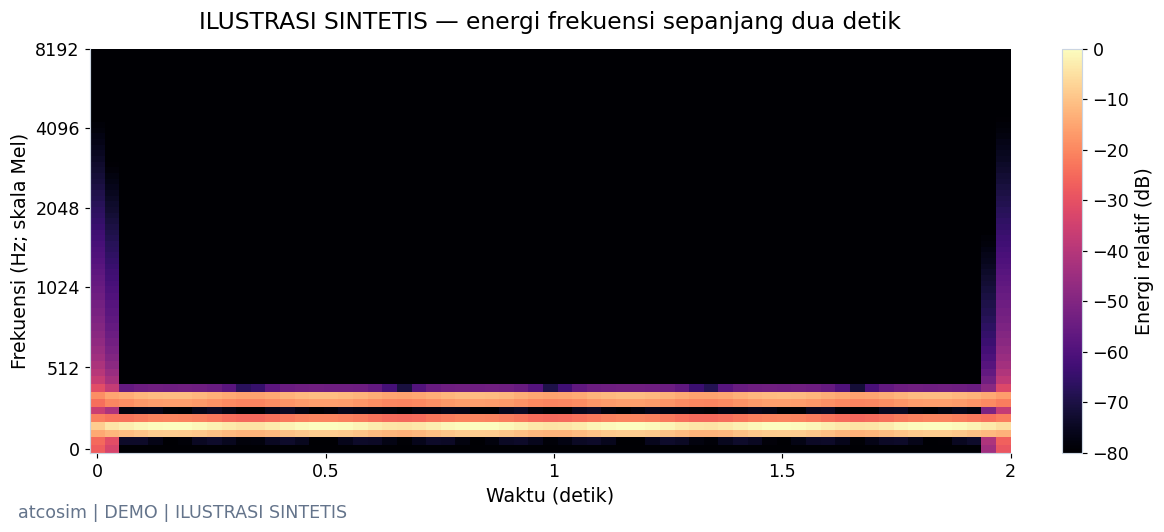

**Yang terlihat:** Energi terkonsentrasi di frekuensi harmonik yang dipakai membentuk sinyal buatan.

**Artinya:** Spektrogram memisahkan informasi waktu dan frekuensi yang tidak terlihat pada satu angka RMS.

**Perlu diingat:** Mel menekankan resolusi frekuensi menurut persepsi pendengaran; bukan indikator fatigue.

*Sumber: `20261022T081753373596Z_seed42_72a678` · CACHED + contoh diproses langsung.*

In [7]:
import librosa
import librosa.display
mel_power = librosa.feature.melspectrogram(y=synthetic_prepared, sr=16000, n_mels=64)
log_mel = librosa.power_to_db(mel_power, ref=np.max)
fig, ax = plt.subplots(layout='constrained')
image = librosa.display.specshow(log_mel, sr=16000, x_axis='time', y_axis='mel', ax=ax, cmap='magma')
ax.set(xlabel='Waktu (detik)', ylabel='Frekuensi (Hz; skala Mel)',
       title='ILUSTRASI SINTETIS — energi frekuensi sepanjang dua detik')
fig.colorbar(image, ax=ax, label='Energi relatif (dB)')
audio_book.show(fig, 'logmel_sintetis',
                'Energi terkonsentrasi di frekuensi harmonik yang dipakai membentuk sinyal buatan.',
                'Spektrogram memisahkan informasi waktu dan frekuensi yang tidak terlihat pada satu angka RMS.',
                'Mel menekankan resolusi frekuensi menurut persepsi pendengaran; bukan indikator fatigue.', synthetic=True)

## 4. Feature engineering: dari spektrum ke tabel

**eGeMAPS** adalah paket 88 ringkasan fitur akustik, termasuk nada, energi, spektrum, dan kualitas suara. **MFCC** (*Mel-frequency cepstral coefficients*) merangkum bentuk spektrum; 13 koefisien dihitung sepanjang waktu, lalu masing-masing diringkas dengan rerata dan simpangan baku: **13 × 2 = 26**.

Satu nilai fitur belum memiliki arti klinis. Unit antarfitur berbeda: pitch semitone bukan Hz, loudness bukan RMS, dan nilai MFCC bersifat koefisien. Tabel contoh asli di atas sengaja hanya menampilkan beberapa kolom.

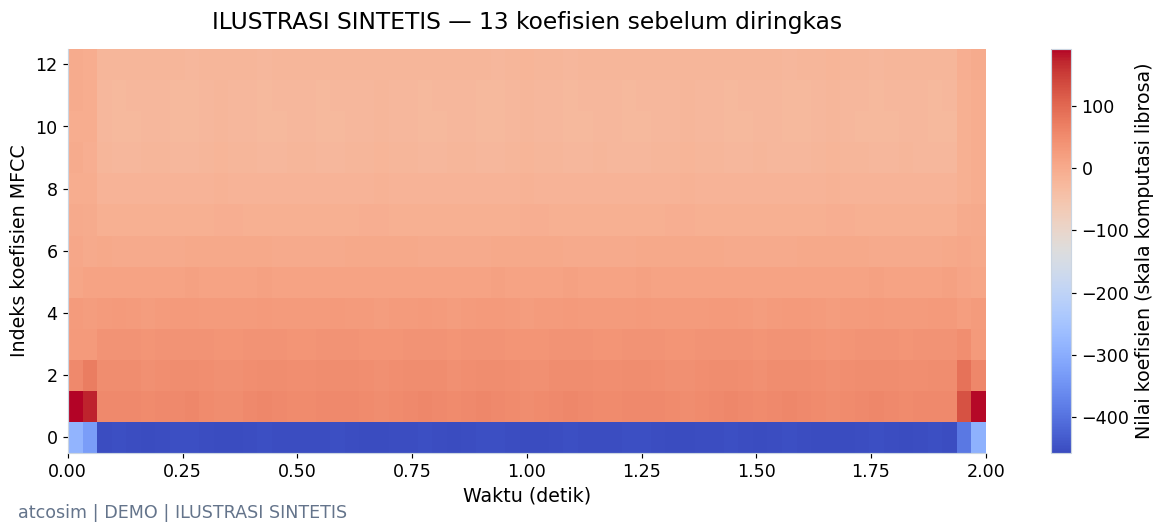

**Yang terlihat:** Setiap baris mengikuti satu koefisien; tabel model merangkum rerata dan variasinya.

**Artinya:** Ringkasan mengubah sinyal berdurasi berbeda menjadi vektor dengan panjang tetap.

**Perlu diingat:** Matriks ini sintetis; 114 fitur eksperimen dihitung dari audio ATCOSIM asli.

*Sumber: `20261022T081753373596Z_seed42_72a678` · CACHED + contoh diproses langsung.*

In [8]:
synthetic_mfcc = librosa.feature.mfcc(y=synthetic_prepared, sr=16000, n_mfcc=13)
fig, ax = plt.subplots(layout='constrained')
image = ax.imshow(synthetic_mfcc, aspect='auto', origin='lower', cmap='coolwarm',
                  extent=[0, 2, -0.5, 12.5])
ax.set(xlabel='Waktu (detik)', ylabel='Indeks koefisien MFCC',
       title='ILUSTRASI SINTETIS — 13 koefisien sebelum diringkas')
fig.colorbar(image, ax=ax, label='Nilai koefisien (skala komputasi librosa)')
audio_book.show(fig, 'mfcc_sintetis',
                'Setiap baris mengikuti satu koefisien; tabel model merangkum rerata dan variasinya.',
                'Ringkasan mengubah sinyal berdurasi berbeda menjadi vektor dengan panjang tetap.',
                'Matriks ini sintetis; 114 fitur eksperimen dihitung dari audio ATCOSIM asli.', synthetic=True)

## 5. Ekstraksi seluruh subset dan quality control

Pada **FULL**, loop berikut benar-benar membaca semua file dan mengekstrak fiturnya. Pada **DEMO**, tabel seluruh subset diambil dari run tersimpan yang telah diverifikasi, sedangkan contoh asli tetap dihitung langsung. Sampel hening/terlalu pendek menghasilkan flag dan nilai hilang, bukan fitur suara nol yang dianggap valid.

In [9]:
if RUN_MODE == 'FULL':
    extraction_started = time.perf_counter()
    audio_rows = []
    for row in audio_manifest.to_dict('records'):
        audio_rows.append({**row, **extract_file(row['original_path'], config['audio'])})
    audio_features = pd.DataFrame(audio_rows)
    audio_run.features(audio_features, audio_columns, 'audio-egemapsv02-mfcc13-v1')
    audio_run.log('extract_all_audio', {'rows': len(audio_features), 'seconds': time.perf_counter()-extraction_started})
else:
    audio_features = pd.read_parquet(audio_run.path / 'features/features.parquet')
np.testing.assert_allclose(audio_features.loc[audio_features.sample_id.eq(sample_audio.sample_id), audio_columns].iloc[0].to_numpy(float),
                           np.array([live_audio_features[c] for c in audio_columns]), equal_nan=True, rtol=1e-5)
audio_qc = {'rows': len(audio_features), 'subjects': int(audio_features.subject_id.nunique()),
            'sessions': int(audio_features.session_id.nunique()),
            'duration_seconds': float(audio_features.duration_seconds.sum()),
            'feature_missing_fraction': float(audio_features[audio_columns].isna().mean().mean()),
            'quality_counts': audio_features.quality.value_counts().to_dict(),
            'evaluation_rows': len(audio_features)}
display(audio_features[['duration_seconds', 'source_sample_rate', 'source_channels', 'quality']].head())
display(pd.DataFrame([audio_qc]).drop(columns='quality_counts'))

,duration_seconds,source_sample_rate,source_channels,quality
0,3.299812,16000,1,ok
1,4.660000,16000,1,ok
2,4.229813,16000,1,ok
3,2.640000,16000,1,ok
4,3.910000,16000,1,ok


,rows,subjects,sessions,duration_seconds,feature_missing_fraction,evaluation_rows
0,100,1,1,425.614688,0.0,100


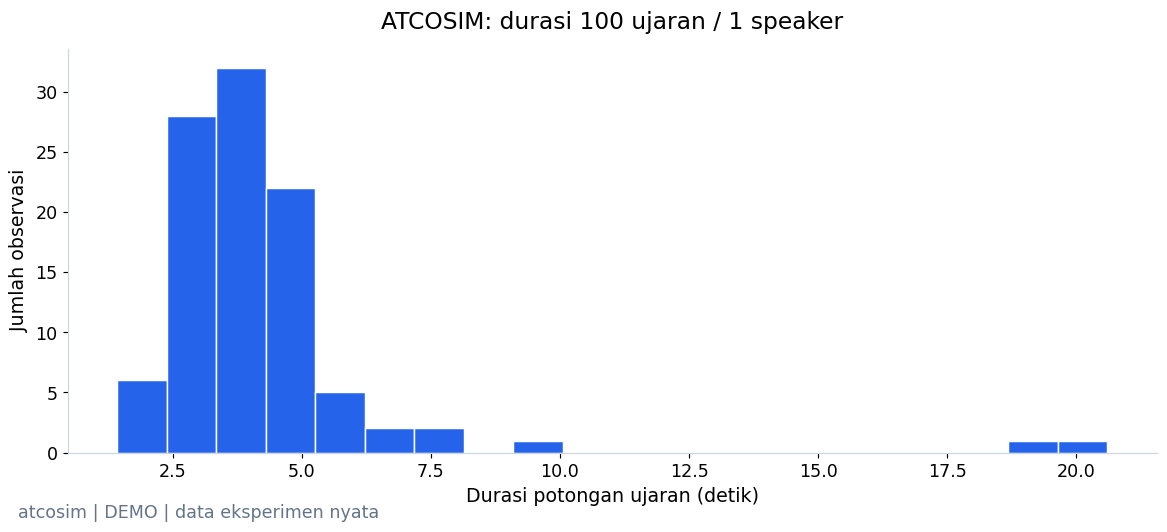

**Yang terlihat:** Total audio 425.61 detik; median ujaran 3.92 detik.

**Artinya:** Durasi bervariasi, sehingga ringkasan fitur berdimensi tetap membantu menyusun tabel.

**Perlu diingat:** Ini durasi potongan rekaman, bukan waktu speech bersih hasil VAD atau sesi kontinu.

*Sumber: `20261022T081753373596Z_seed42_72a678` · CACHED + contoh diproses langsung.*

In [10]:
fig = histogram(audio_features.duration_seconds, 'Durasi potongan ujaran (detik)',
                f'ATCOSIM: durasi {len(audio_features)} ujaran / {audio_features.subject_id.nunique()} speaker', COLORS['audio'])
audio_book.show(fig, 'distribusi_durasi',
                f'Total audio {audio_qc["duration_seconds"]:.2f} detik; median ujaran {audio_features.duration_seconds.median():.2f} detik.',
                'Durasi bervariasi, sehingga ringkasan fitur berdimensi tetap membantu menyusun tabel.',
                'Ini durasi potongan rekaman, bukan waktu speech bersih hasil VAD atau sesi kontinu.')

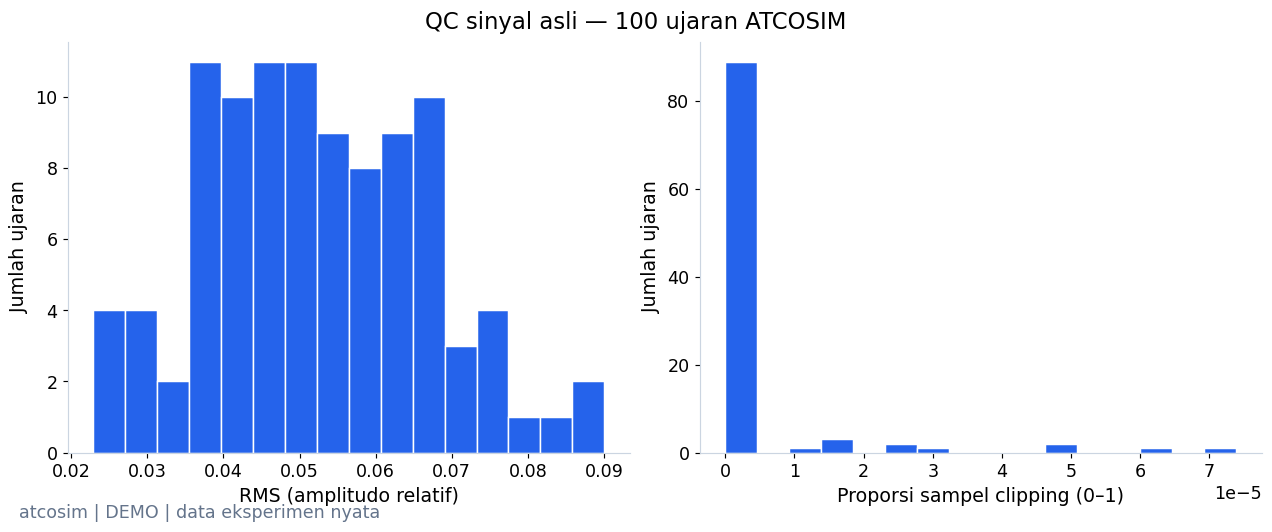

**Yang terlihat:** RMS median 0.051524; clipping maksimum 0.000074.

**Artinya:** Pemeriksaan ini mendeteksi persoalan level sinyal sebelum fitur dipakai model.

**Perlu diingat:** RMS dan clipping bukan estimasi SNR, VAD, atau kondisi fatigue.

*Sumber: `20261022T081753373596Z_seed42_72a678` · CACHED + contoh diproses langsung.*

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8), layout='constrained')
for ax, column, label in zip(axes, ['rms', 'clipping_fraction'], ['RMS (amplitudo relatif)', 'Proporsi sampel clipping (0–1)']):
    ax.hist(audio_features[column], bins=16, color=COLORS['audio'], edgecolor='white')
    ax.set(xlabel=label, ylabel='Jumlah ujaran')
    ax.ticklabel_format(axis='x', style='sci', scilimits=(-3, 3))
fig.suptitle(f'QC sinyal asli — {len(audio_features)} ujaran ATCOSIM')
audio_book.show(fig, 'rms_dan_clipping',
                f'RMS median {audio_features.rms.median():.6f}; clipping maksimum {audio_features.clipping_fraction.max():.6f}.',
                'Pemeriksaan ini mendeteksi persoalan level sinyal sebelum fitur dipakai model.',
                'RMS dan clipping bukan estimasi SNR, VAD, atau kondisi fatigue.')

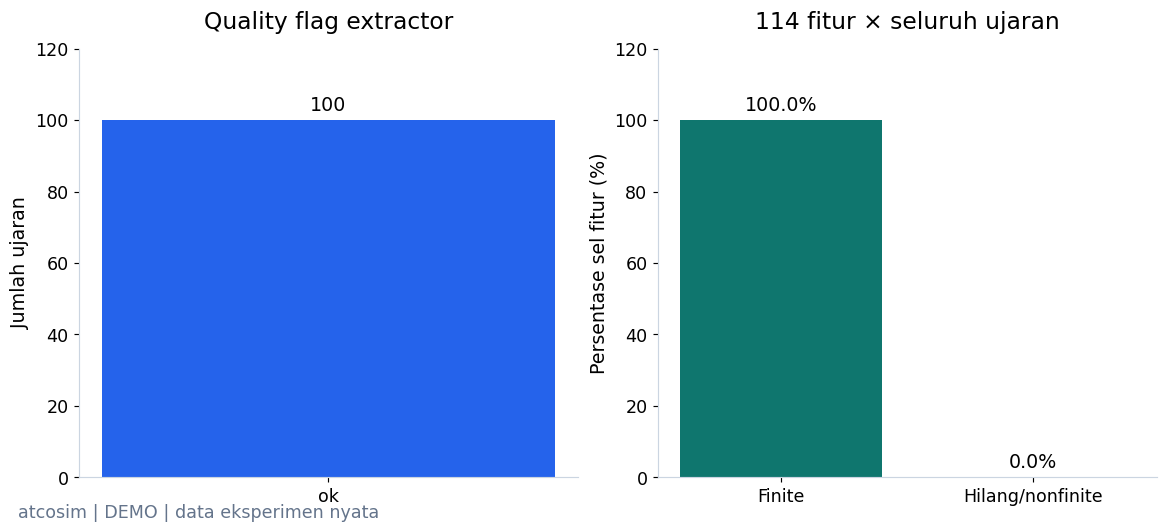

**Yang terlihat:** 100 ujaran tersedia; 100.0% sel fitur finite.

**Artinya:** Pipeline dapat membentuk tabel tanpa mengarang pengukuran pada sampel tidak valid.

**Perlu diingat:** Quality ok adalah kelayakan teknis ekstraksi, bukan validasi biomarker atau generalisasi.

*Sumber: `20261022T081753373596Z_seed42_72a678` · CACHED + contoh diproses langsung.*

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.8), layout='constrained')
counts = audio_features.quality.value_counts()
bars = axes[0].bar(counts.index, counts.values, color=COLORS['audio'])
axes[0].bar_label(bars, padding=4)
axes[0].set(ylabel='Jumlah ujaran', title='Quality flag extractor', ylim=(0, counts.max()*1.2))
finite_percent = 100 * np.isfinite(audio_features[audio_columns].to_numpy(float)).mean()
bars = axes[1].bar(['Finite', 'Hilang/nonfinite'], [finite_percent, 100-finite_percent],
                   color=[COLORS['fusion'], COLORS['error']])
axes[1].bar_label(bars, fmt='%.1f%%', padding=4)
axes[1].set(ylabel='Persentase sel fitur (%)', title='114 fitur × seluruh ujaran', ylim=(0, 120))
audio_book.show(fig, 'kualitas_dan_missingness',
                f'{int(audio_features.audio_available.sum())} ujaran tersedia; {finite_percent:.1f}% sel fitur finite.',
                'Pipeline dapat membentuk tabel tanpa mengarang pengukuran pada sampel tidak valid.',
                'Quality ok adalah kelayakan teknis ekstraksi, bukan validasi biomarker atau generalisasi.')

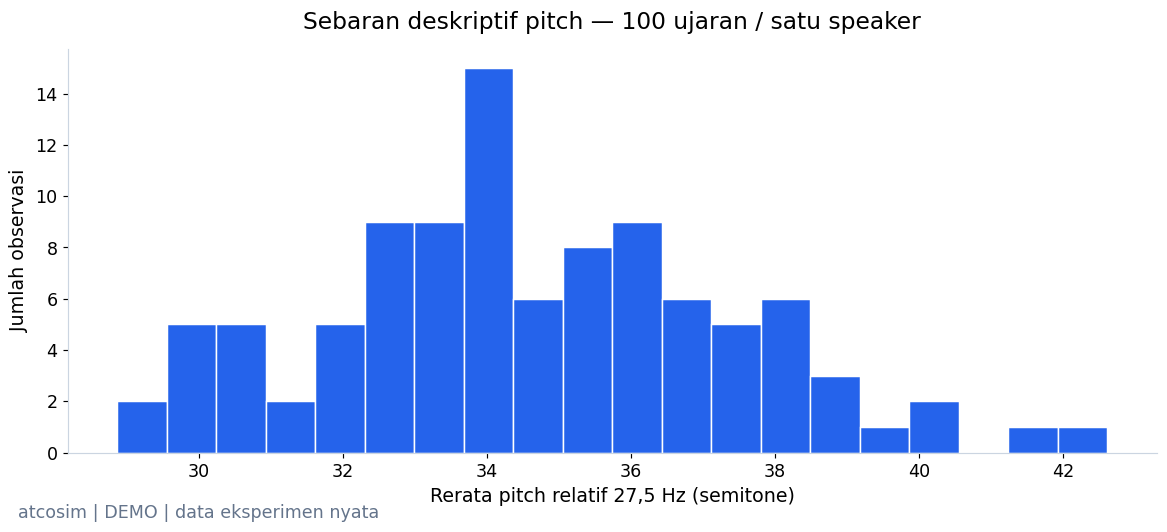

**Yang terlihat:** Median fitur pitch pada subset 34.30 semitone.

**Artinya:** Satu fitur memiliki variasi antarujaran meskipun berasal dari speaker yang sama.

**Perlu diingat:** Tidak ada kelompok fatigue/non-fatigue untuk menguji apakah variasi ini berkaitan dengan kelelahan.

*Sumber: `20261022T081753373596Z_seed42_72a678` · CACHED + contoh diproses langsung.*

In [13]:
pitch_column = next(c for c in audio_columns if 'F0semitoneFrom27.5Hz_sma3nz_amean' in c)
fig = histogram(audio_features[pitch_column].to_numpy(float), 'Rerata pitch relatif 27,5 Hz (semitone)',
                f'Sebaran deskriptif pitch — {len(audio_features)} ujaran / satu speaker', COLORS['audio'])
audio_book.show(fig, 'distribusi_pitch',
                f'Median fitur pitch pada subset {audio_features[pitch_column].median():.2f} semitone.',
                'Satu fitur memiliki variasi antarujaran meskipun berasal dari speaker yang sama.',
                'Tidak ada kelompok fatigue/non-fatigue untuk menguji apakah variasi ini berkaitan dengan kelelahan.')

## 6. Temuan, keterbatasan, dan langkah berikutnya

Pipeline menghasilkan representasi akustik dan QC yang dapat diperiksa. Subset first-100 dari satu speaker/sesi belum menguji variasi aksen, operator, mikrofon, atau radio terkompresi. Tidak ada timeline pilot yang sah untuk menghitung latency respons, dan tidak ada label fatigue untuk melatih classifier.

Kandidat berikutnya adalah IEEE ATC Radiotelephony Fatigue Corpus, DOI `10.21227/70sz-mj23`. **Menurut pembaruan pengguna pada spesifikasi v3, permintaan akses sudah dikirim; akses/data belum tersedia.** Notebook tidak mencoba mengunduh atau melewati login. Setelah akses sah, label, speaker, channel, duplikasi dan split perlu diaudit terlebih dahulu.

## 7. Provenance dan reproduksi

FULL menyimpan manifest sumber, konfigurasi, versi environment, schema, Parquet, QC, log dan grafik. File model/prediksi tidak berlaku karena tidak ada label. Grafik ilustrasi sintetis tidak digunakan sebagai data eksperimen.

In [14]:
audio_book.finish()
if RUN_MODE == 'FULL':
    audio_metrics = metrics_base(audio_run, {}, {}, {}, baseline=None)
    audio_run.complete(audio_metrics, audio_qc, warning_records)
display(pd.DataFrame([{'Run ID': audio_run.manifest['run_id'], 'Mode': RUN_MODE,
                       'Ujaran': len(audio_features), 'Fitur': len(audio_columns),
                       'Metrik supervised': 'N/A — no_fatigue_labels',
                       'Artifact': str(audio_run.path.relative_to(ROOT))}]))
warning_context.__exit__(None, None, None)

,Run ID,Mode,Ujaran,Fitur,Metrik supervised,Artifact
0,20261022T081753373596Z_seed42_72a678,DEMO,100,114,N/A — no_fatigue_labels,runs/atcosim_audio/20261022T081753373596Z_seed...


**Kesimpulan:** data suara ATC asli berhasil masuk ke tabel fitur, tetapi tidak menghasilkan skor fatigue. Untuk mengulang seluruh subset, jalankan `ATC_NOTEBOOK_MODE=FULL .venv/bin/python scripts/10_execute_notebook_v3.py --mode FULL --notebook 01_audio_analysis.ipynb`. Mode DEMO adalah pilihan presentasi; petunjuk lengkap ada di [README v3](README.md).